In [1]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

In [2]:
from ISLP import load_data
carseats = load_data('Carseats')

In [3]:
carseats['HighSales'] = (carseats['Sales'] > 8).astype(int)
carseats = carseats.drop(columns=['Sales'])
print(carseats['HighSales'].value_counts())

HighSales
0    236
1    164
Name: count, dtype: int64


In [10]:
print(carseats.shape)
carseats.head()

(400, 11)


,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US,HighSales
0,138,73,11,276,120,Bad,42,17,Yes,Yes,1
1,111,48,16,260,83,Good,65,10,Yes,Yes,1
2,113,35,10,269,80,Medium,59,12,Yes,Yes,1
3,117,100,4,466,97,Medium,55,14,Yes,Yes,0
4,141,64,3,340,128,Bad,38,13,Yes,No,0


In [8]:
print(carseats.isna().sum())

print()

print(carseats.dtypes)

CompPrice      0
Income         0
Advertising    0
Population     0
Price          0
ShelveLoc      0
Age            0
Education      0
Urban          0
US             0
HighSales      0
dtype: int64

CompPrice         int64
Income            int64
Advertising       int64
Population        int64
Price             int64
ShelveLoc      category
Age               int64
Education         int64
Urban          category
US             category
HighSales         int64
dtype: object


In [12]:
X = pd.get_dummies(carseats.drop(columns='HighSales'), columns=['ShelveLoc', 'Urban','US']).astype(int)
y = carseats['HighSales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y)

print(X_train.shape, X_test.shape)

(280, 14) (120, 14)


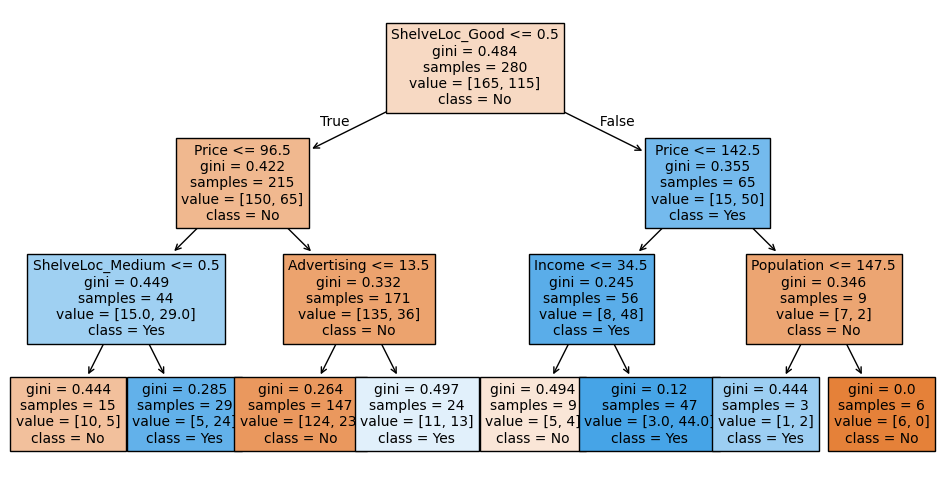

Train accuracy: 0.814
Test accuracy:  0.683


In [14]:
tree = DecisionTreeClassifier(max_depth=3, random_state=0)
tree.fit(X_train, y_train)

plt.figure(figsize=(12, 6))

plot_tree(tree,
          feature_names=list(X.columns),
          class_names=['No', 'Yes'],
          filled=True,
          fontsize=10)
plt.show()

print('Train accuracy:', round(tree.score(X_train, y_train), 3))
print('Test accuracy: ', round(tree.score(X_test, y_test), 3))

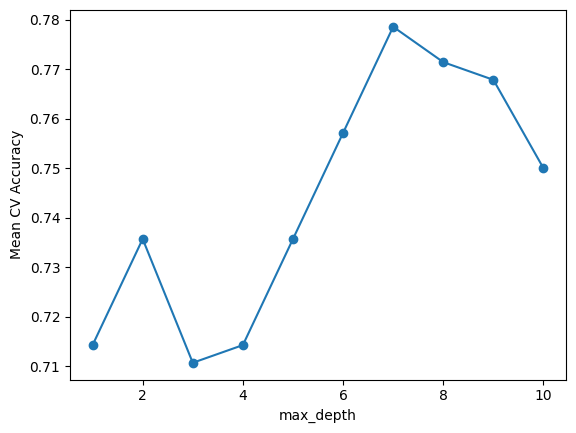

Best max_depth: 7
Best Tree: 0.717


In [21]:
depths = range(1,11)
cv_accuracies = []
for d in depths:
  tree2 = DecisionTreeClassifier(max_depth = d, random_state = 0)
  tree2.fit(X_train, y_train)

  scores = cross_val_score(tree2, X_train, y_train, cv=5, scoring='accuracy')
  cv_accuracies.append(scores.mean())

plt.plot(depths, cv_accuracies, marker='o')
plt.xlabel('max_depth'); plt.ylabel('Mean CV Accuracy'); plt.show()

best_d = list(depths)[int(np.argmax(cv_accuracies))]
best_tree = DecisionTreeClassifier(max_depth=best_d, random_state=0).fit(X_train, y_train)

def accuracy(model): return model.score(X_test,y_test)

print('Best max_depth:', best_d)
print('Best Tree:', round(accuracy(best_tree), 3))

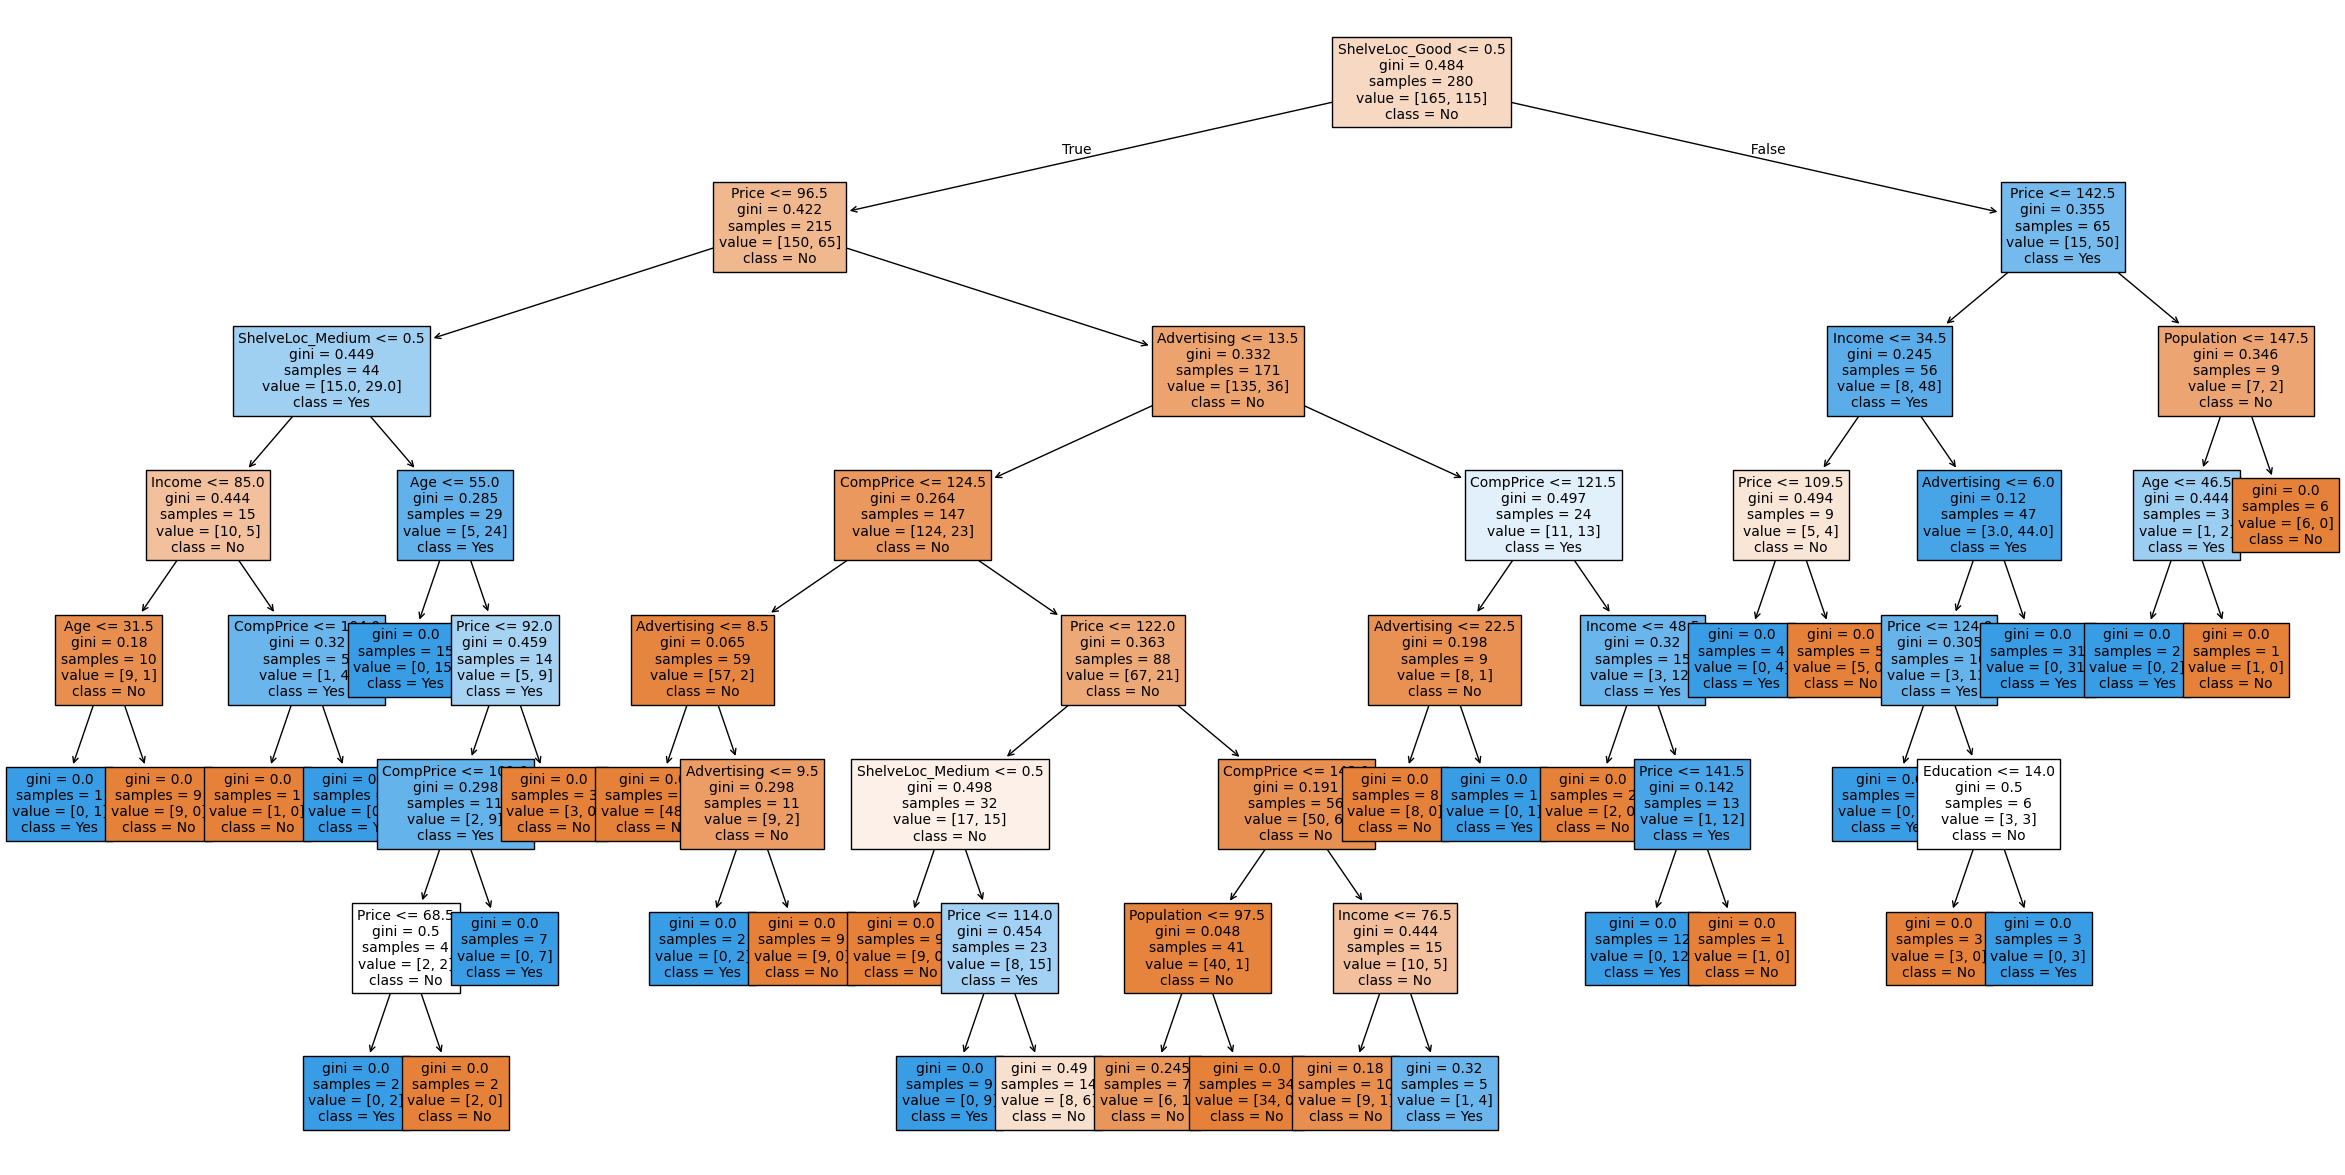

Train accuracy: 0.968
Test accuracy:  0.717


In [25]:
tree3 = DecisionTreeClassifier(max_depth=7, random_state=0)
tree3.fit(X_train, y_train)

plt.figure(figsize=(30, 15))

plot_tree(tree3,
          feature_names=list(X.columns),
          class_names=['No', 'Yes'],
          filled=True,
          fontsize=10)
plt.show()

print('Train accuracy:', round(tree3.score(X_train, y_train), 3))
print('Test accuracy: ', round(tree3.score(X_test, y_test), 3))

*1. Interpreting the tree: Which predictor was selected for the first split (root)? What does this split tell us about sales?*

ShelveLoc was the predictor chosen for the first split. This tells us that ShelveLoc is the most important feature when it comes to predicting whether there are HighSales.

*2. Choosing tree depth: According to your cross-validation graph, which depth performed best? Why should we use cross-validation rather than test accuracy to choose the depth?*

The depth that perfomed the best was 7. Test accuracy is meant to be seen at the very end so that it gives an unbiased evaluation of how well the model will perform when given new data. Using test accuracy would cause data leakage. Cross-validation is more stable and reliable as performing multiple splits and averaging them helps smooth out the noise.


*3. Overfitting: Does increasing tree depth always improve cross-validation accuracy? Explain using your graph.*

No, increasing tree depth does not always improve cross-validation accuracy. As the graph showed, after a depth of 7, the cross validation actually dropped. As the depth grows, a tree becomes more complex, which can lead to overfitting because the it starts to learn random noise.

*1. What does a leaf predict in a classification tree? In a regression tree?*

A leaf in a classification tree predicts a categorical label. A leaf in a regression tree predicts a numerical value.

*2. Why did the full tree reach 100% training accuracy but do worse on the test set?*

A full tree will always completely memorize the training data, overfitting. Thus, when presented with unseen data, it performed poorly.

*3.Give two ways to limit tree complexity. Which one did cross-validation help you tune?*

You can limit tree complexity with either pre-pruning or post-pruning. Cross-validation helped me tune pre-pruning, as I was limiting the tree on how deep it could grow.

*4. Why do we not need to scale features before fitting a tree?*

In a tree, features are evaluated independently. This means that variables with larger numbers can't overpower smaller variables.

*5. A teammate says "Age has importance 0, so it is irrelevant to heart disease." What is wrong with that claim? (answer in terms of reducing impurity)*

Having an importance of 0 does not mean it is irrelevant to heart disease. If two features have similar information, a tree will pick one and give the other an importance of 0. This means that feature was never chosen to split a node and therefore contributed zero reduction in impurity.

*6. Name one strength and one weakness of a single decision tree that you saw in this lab.*

Strength: A single decision tree is easy to visualize and interpret.

Weakness: It was able to overfit very easily when left unconstrained.